# 03 - Combined dataset (OSF sensors + parcels)

Pools the two cohorts to increase training data, which is the bottleneck identified in the
sensor-level results.

They combine because BrainOmni's tokenizer compresses any channel count to 16 tokens, so after
tokenization both look identical in shape:

```
OSF subject     271 sensors -> (16, 160, D)
parcel subject  210 parcels -> (16, 160, D)
```

**One correctness issue to settle: subject overlap.** The parcel cohort has 77 AD and the OSF cohort
has 78, close enough that these may be substantially the same people. If so, pooling puts the same
person in twice, once as sensors and once as parcels. That is not extra data, and if the two copies
land in different cross-validation folds the model trains on a person and is then tested on them,
which inflates accuracy for no real reason.

`SUBJECT_GROUPS` below handles this. Leave it `None` only if you know the cohorts are disjoint.

In [8]:
import os, sys, json
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
import numpy as np, torch
import torch.nn.functional as F
sys.path.insert(0, '/Users/faenegoro/Documents/Neuroimaging/BrainOmni')
from brainomni.model import BrainOmni

OSF  = '../data/preprocessed'
OUT  = '../results_parcel'
CKPT_ROOT = '/Users/faenegoro/Documents/Neuroimaging/BrainOmni/ckpt_collection'
MODEL, SUFFIX = 'base', 'cortical'
sfx = '_base' if MODEL == 'base' else ''

device = torch.device('mps') if torch.backends.mps.is_available() else torch.device('cpu')

# If the cohorts overlap, supply an array of length (148 + 161) giving a shared id for
# rows that are the same person, so CV keeps them together. None = assume disjoint.
SUBJECT_GROUPS = None

In [9]:
osf1 = np.load(f'{OSF}/proj_out1{sfx}.npy'); osf2 = np.load(f'{OSF}/proj_out2{sfx}.npy')
osf_y = np.load(f'{OSF}/labels.npy')
par1 = np.load(f'{OUT}/parcel_proj_out1_{MODEL}_{SUFFIX}.npy')
par2 = np.load(f'{OUT}/parcel_proj_out2_{MODEL}_{SUFFIX}.npy')
par_y = np.load(f'{OUT}/parcel_labels_{SUFFIX}.npy')

print('OSF   :', osf1.shape, '| AD', int((osf_y==1).sum()), 'Control', int((osf_y==0).sum()))
print('parcel:', par1.shape, '| AD', int((par_y==1).sum()), 'Control', int((par_y==0).sum()))
assert osf1.shape[1:] == par1.shape[1:], f'shape mismatch: {osf1.shape[1:]} vs {par1.shape[1:]}'
print('\ntoken shapes match, safe to concatenate')

proj1  = np.concatenate([osf1, par1]).astype(np.float32)
proj2  = np.concatenate([osf2, par2]).astype(np.float32)
labels = np.concatenate([osf_y, par_y])
source = np.array(['osf'] * len(osf_y) + ['parcel'] * len(par_y))
N = len(labels)
print(f'combined: {N} subjects | AD {int((labels==1).sum())} | Control {int((labels==0).sum())}')

OSF   : (148, 16, 160, 512) | AD 78 Control 70
parcel: (161, 16, 160, 512) | AD 77 Control 84

token shapes match, safe to concatenate
combined: 309 subjects | AD 155 | Control 154


In [ ]:
cfg  = json.load(open(f'{CKPT_ROOT}/{MODEL}/model_cfg.json'))
ckpt = torch.load(f'{CKPT_ROOT}/{MODEL}/BrainOmni.pt', map_location='cpu', weights_only=True)
model = BrainOmni(**cfg); model.load_state_dict(ckpt, strict=False)
for p in model.parameters():
    p.requires_grad = False
model = model.to(device).eval()

feats = []
with torch.no_grad():
    for i in range(N):
        x1 = torch.tensor(proj1[i]).unsqueeze(0).to(device)
        x2 = torch.tensor(proj2[i]).unsqueeze(0).to(device)
        for b in list(model.blocks)[:-1]:
            x1 = b(x1); x2 = b(x2)
        x1 = F.normalize(x1, p=2.0, dim=-1, eps=1e-6).mean(dim=2)
        x2 = F.normalize(x2, p=2.0, dim=-1, eps=1e-6).mean(dim=2)
        feats.append(((x1 + x2) / 2).flatten().cpu().numpy())
X = np.stack(feats)
np.save(f'{OUT}/combined_frozen_{MODEL}_{SUFFIX}.npy', X)
print('combined frozen features:', X.shape)

/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


In [ ]:
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_validate
from sklearn.linear_model import LogisticRegression

if SUBJECT_GROUPS is None:
    cv, groups = StratifiedKFold(5, shuffle=True, random_state=123), None
    print('CV: StratifiedKFold (assumes the two cohorts are disjoint)')
else:
    cv, groups = StratifiedGroupKFold(5, shuffle=True, random_state=123), SUBJECT_GROUPS
    print('CV: StratifiedGroupKFold (keeps repeated subjects in the same fold)')

r = cross_validate(LogisticRegression(max_iter=2000), X, labels, cv=cv, groups=groups,
                   scoring=['accuracy', 'roc_auc'])
print(f'\ncombined ({N} subjects): accuracy {r["test_accuracy"].mean():.3f} | AUC {r["test_roc_auc"].mean():.3f}')

# Each cohort alone, for comparison.
for name in ['osf', 'parcel']:
    m = source == name
    rr = cross_validate(LogisticRegression(max_iter=2000), X[m], labels[m],
                        cv=StratifiedKFold(5, shuffle=True, random_state=123),
                        scoring=['accuracy', 'roc_auc'])
    print(f'{name:7s} alone ({m.sum():3d} subjects): accuracy {rr["test_accuracy"].mean():.3f} | AUC {rr["test_roc_auc"].mean():.3f}')

CV: StratifiedKFold (assumes the two cohorts are disjoint)

combined (309 subjects): accuracy 0.832 | AUC 0.898
osf     alone (148 subjects): accuracy 0.831 | AUC 0.859
parcel  alone (161 subjects): accuracy 0.850 | AUC 0.922


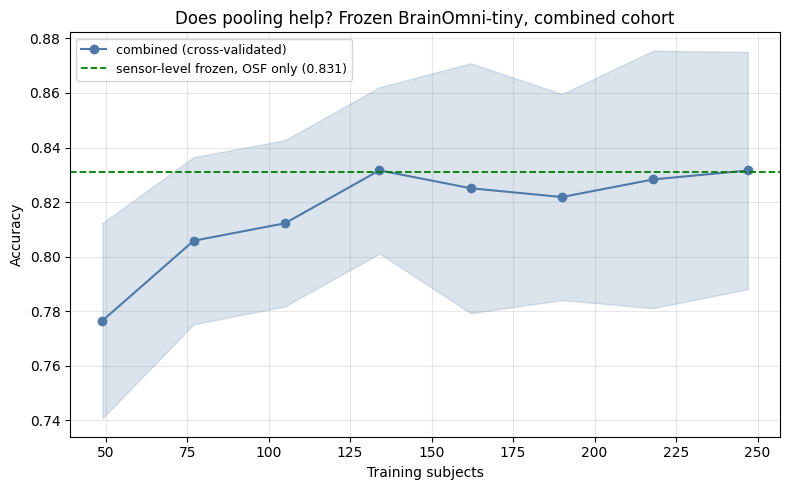

If the curve is still rising at the right edge, more data would still help.
If it has flattened, the bottleneck is the representation rather than sample size.


In [ ]:
# Does pooling actually help? Sample-size curve on the combined set.
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, StratifiedKFold
from sklearn.linear_model import LogisticRegression

sizes, train_s, test_s = learning_curve(
    LogisticRegression(max_iter=2000), X, labels,
    train_sizes=np.linspace(0.2, 1.0, 8),
    cv=StratifiedKFold(5, shuffle=True, random_state=123), scoring='accuracy',
    shuffle=True, random_state=123)   # labels sit in blocks (OSF then parcel, AD then
                                      # control), so subsets must be shuffled or the
                                      # smallest training size is single-class

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sizes, test_s.mean(1), 'o-', color='#4E79A7', label='combined (cross-validated)')
ax.fill_between(sizes, test_s.mean(1) - test_s.std(1), test_s.mean(1) + test_s.std(1),
                color='#4E79A7', alpha=0.2)
ax.axhline(0.831, color='green', ls='--', lw=1.3, label='sensor-level frozen, OSF only (0.831)')
ax.set_xlabel('Training subjects'); ax.set_ylabel('Accuracy')
ax.set_title(f'Does pooling help? Frozen BrainOmni-{MODEL}, combined cohort')
ax.legend(fontsize=9); ax.grid(alpha=0.3); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig(f'{OUT}/combined_learning_curve.png', dpi=150); plt.show()

print('If the curve is still rising at the right edge, more data would still help.')
print('If it has flattened, the bottleneck is the representation rather than sample size.')

In [ ]:
# Cohort comparison: does pooling the two datasets help?
# White dots are individual folds. The spread matters as much as the mean --
# OSF's larger error bar is mostly a test-fold-size effect (~30 subjects per
# fold vs ~62 for combined), not evidence that the model is less consistent.
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression

y_osf = np.load(f'{OSF}/labels.npy')
y_par = np.load(f'{OUT}/parcel_labels_cortical.npy')
X_all = np.load(f'{OUT}/combined_frozen_{MODEL}_{SUFFIX}.npy')
cv = StratifiedKFold(5, shuffle=True, random_state=123)

sets = [('OSF only\n(sensor, 271ch)', X_all[:148], y_osf, '#E15759'),
        ('Parcel only\n(source, 210 regions)', X_all[148:], y_par, '#4E79A7'),
        ('Combined\n(both cohorts)', X_all, np.concatenate([y_osf, y_par]), '#59A14F')]

R = []
for tag, X, y, col in sets:
    r = cross_validate(LogisticRegression(max_iter=2000), X, y, cv=cv, scoring=['accuracy', 'roc_auc'])
    R.append(dict(tag=tag, col=col, n=len(y), acc=r['test_accuracy'], auc=r['test_roc_auc'],
                  base=max(np.bincount(y)) / len(y)))

fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), gridspec_kw={'width_ratios': [1.15, 1.15, 1.1]})

# panels 1-2: mean bars with per-fold points overlaid, so spread is visible not just implied
for ax, key, name in [(axes[0], 'acc', 'Accuracy'), (axes[1], 'auc', 'AUC')]:
    xs = np.arange(len(R))
    means = [r[key].mean() for r in R]
    sds = [r[key].std() for r in R]
    ax.bar(xs, means, 0.6, yerr=sds, color=[r['col'] for r in R], alpha=.85,
           capsize=6, error_kw=dict(lw=1.4, ecolor='#333'))
    rng = np.random.default_rng(0)
    for i, r in enumerate(R):
        ax.scatter(np.full(5, i) + rng.uniform(-.13, .13, 5), r[key],
                   s=34, color='white', edgecolor='#333', lw=1.1, zorder=3)
    for i, m in enumerate(means):
        ax.text(i, 0.487, f'{m:.3f}', ha='center', va='bottom',
                fontweight='bold', fontsize=12, color='white')
    if key == 'acc':
        ax.axhline(R[2]['base'], color='#888', ls=':', lw=1.5)
        ax.text(-0.45, R[2]['base'] + .012, 'chance', color='#888', fontsize=8.5, ha='left')
    ax.set_xticks(xs); ax.set_xticklabels([r['tag'] for r in R], fontsize=9)
    ax.set_ylim(0.45, 1.05); ax.set_ylabel(name)
    ax.set_title(f'{name} — frozen BrainOmni-{MODEL} + LR', fontsize=11, fontweight='bold')
    ax.grid(axis='y', alpha=.3); ax.set_axisbelow(True)

# panel 3: the numbers themselves
axes[2].axis('off')
short = ['OSF (sensor)', 'Parcel (source)', 'Combined']
rows = [[short[i], str(r['n']),
         f"{r['acc'].mean():.3f} ± {r['acc'].std():.3f}",
         f"{r['auc'].mean():.3f} ± {r['auc'].std():.3f}"] for i, r in enumerate(R)]
t = axes[2].table(cellText=rows, colLabels=['Cohort', 'N', 'Accuracy', 'AUC'],
                  cellLoc='center', loc='center', colWidths=[.34, .11, .28, .28])
t.auto_set_font_size(False); t.set_fontsize(10); t.scale(1, 2.0)
for (row, _), c in t.get_celld().items():
    c.set_edgecolor('#bbb')
    if row == 0:
        c.set_facecolor('#eee'); c.set_text_props(fontweight='bold')
    elif row == 2:
        c.set_facecolor('#eaf1f8')          # highlight the winner
axes[2].set_title('Summary (5-fold CV, seed 123)', fontsize=11, fontweight='bold', y=.80)
axes[2].text(.5, .17, 'White dots are individual folds.\nWider spread = less reliable estimate.',
             ha='center', fontsize=9, color='#555', transform=axes[2].transAxes)

plt.tight_layout()
plt.savefig(f'{OUT}/cohort_comparison_{MODEL}.png', dpi=150, bbox_inches='tight')
plt.show()
print('saved', f'{OUT}/cohort_comparison_{MODEL}.png')
for r in R:
    print(f"  {r['tag'][:12]:14s} N={r['n']:3d}  acc {r['acc'].mean():.3f}+/-{r['acc'].std():.3f}  auc {r['auc'].mean():.3f}+/-{r['auc'].std():.3f}")
